# Task 5 — Polynomial OLS and Ridge Regression

## Assigned model

The selected branch is $\xi_{15}=2$.

The displayed model is a degree-10 polynomial:

$$
f_\alpha(x)
=
\alpha_0+\alpha_1x+\cdots+\alpha_{10}x^{10}.
$$

This formula contains 11 coefficients, including the intercept. The calculation follows the displayed formula rather than the inconsistent wording describing ten parameters.

There are 22 supplied observations $(x_i,y_i)$.

## Objectives

1. Calculate the ordinary least-squares coefficient estimates
2. Calculate ridge-regularized coefficient estimates
3. Define and justify the penalty convention and its weight
4. Compare fit error, coefficient shrinkage, and validation performance
5. Explain the numerical methods and limitations

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

data = np.array([
    (15, 1626639709458.76),
    (-6, 215903959.68),
    (17, 5634674657106.69),
    (-14, 948255878968.41),
    (2, 2453.01),
    (12, 176891864016.73),
    (-5, 38455500.59),
    (8, 2741446963.17),
    (-3, 277968.96),
    (-16, 3390875179551.8),
    (4, 2649990.77),
    (-9, 11403619911.64),
    (-11, 89910534374.96),
    (-19, 19608390963199.21),
    (-12, 200804985369.02),
    (-13, 453441370414.22),
    (18, 9897917086496.97),
    (-8, 3816397713.47),
    (-7, 977873055.85),
    (-10, 33506954184.6),
    (20, 29726123569978.77),
    (7, 752826486.45),
], dtype=float)

x = data[:, 0]
y = data[:, 1]

degree = 10
n_parameters = degree + 1
n_observations = len(x)

figure_directory = Path("figures")
figure_directory.mkdir(parents=True, exist_ok=True)

assert n_observations == 22
assert len(np.unique(x)) == n_observations
assert np.all(np.isfinite(data))

print(f"Observations: {n_observations}")
print(f"Polynomial degree: {degree}")
print(f"Coefficients including intercept: {n_parameters}")
print(f"Input range: {x.min():.0f} to {x.max():.0f}")

Observations: 22
Polynomial degree: 10
Coefficients including intercept: 11
Input range: -19 to 20


## Scaling and design matrix

Directly constructing high powers of the original inputs produces columns with very different magnitudes.

Define fixed scaling constants

$$
c=20,\qquad d=10^{13},
$$

and scaled variables

$$
t_i=\frac{x_i}{c},
\qquad
z_i=\frac{y_i}{d}.
$$

The scaled polynomial is

$$
g_\beta(t)=\sum_{j=0}^{10}\beta_jt^j,
$$

so that the predicted response in original units is

$$
\widehat{y}(x)=d\,g_\beta(x/c).
$$

The original polynomial coefficients are recovered by

$$
\alpha_j=\frac{d}{c^j}\beta_j
$$

Define the design matrix A by

$$
A_{ij}=t_i^j,
\qquad i=1,\ldots,22,\quad j=0,\ldots,10.
$$

Because the inputs are distinct, this degree-10 polynomial design has full column rank. A nonzero polynomial of degree at most 10 cannot vanish at all 22 distinct inputs.

Scaling changes the coefficient representation but does not change the set of available polynomial functions. It therefore preserves the OLS fitting problem after conversion back to original units.

For ridge regression, the coefficient representation affects the penalty. The chosen penalty is defined explicitly below.

In [2]:
x_scale = 20.0
y_scale = 1e13

t = x / x_scale
z = y / y_scale

# increases exp value by t when true
A = np.vander(t, N=n_parameters, increasing=True)

# to assess scaling
A_unscaled = np.vander(x, N=n_parameters, increasing=True)

rank = np.linalg.matrix_rank(A)
condition_scaled = np.linalg.cond(A)
condition_unscaled = np.linalg.cond(A_unscaled)

assert rank == n_parameters

print(f"Design matrix shape: {A.shape}")
print(f"Scaled matrix rank: {rank}")
print(f"Unscaled condition number: {condition_unscaled:.3e}")
print(f"Scaled condition number: {condition_scaled:.3e}")

Design matrix shape: (22, 11)
Scaled matrix rank: 11
Unscaled condition number: 1.112e+13
Scaled condition number: 4.913e+03


## Ordinary least squares

The OLS estimate minimizes

$$
J_0(\beta)=\|\mathbf z-A\beta\|_2^2.
$$

Differentiation gives

$$
\nabla J_0(\beta)
=
2A^\mathsf{T}(A\beta-\mathbf z).
$$

Therefore, the minimizer satisfies

$$
A^\mathsf{T}A\widehat{\beta}_{OLS}
=
A^\mathsf{T}\mathbf z.
$$

Since A has full column rank, the OLS solution is unique.

The numerical calculation solves the least-squares problem directly rather than explicitly forming and inverting $A^\mathsf{T}A$.

## Ridge regularization

The chosen ridge objective is

$$
J_\lambda(\beta)
=
\|\mathbf z-A\beta\|_2^2
+
\lambda\sum_{j=1}^{10}\beta_j^2,
\qquad\lambda>0.
$$

The intercept is not penalized because it represents the response level rather than variation with the input.

Let

$$
D=\operatorname{diag}(0,1,\ldots,1).
$$

Then

$$
J_\lambda(\beta)
=
\|\mathbf z-A\beta\|_2^2
+
\lambda\|D\beta\|_2^2.
$$

Differentiating gives

$$
(A^\mathsf{T}A+\lambda D^\mathsf{T}D)
\widehat{\beta}_\lambda
=
A^\mathsf{T}\mathbf z.
$$

Equivalently, the estimate solves the augmented least-squares problem

$$
\min_\beta
\left\|
\begin{pmatrix}
A\\
\sqrt{\lambda}D
\end{pmatrix}\beta
-
\begin{pmatrix}
\mathbf z\\
\mathbf0
\end{pmatrix}
\right\|_2^2.
$$

This augmented formulation is used for the computation.

## Meaning of the penalty in original coordinates

Since $\beta_j=c^j\alpha_j/d$, multiplying the scaled objective by $d^2$ gives the equivalent original-response objective

$$
\sum_{i=1}^{22}
\left(y_i-f_\alpha(x_i)\right)^2
+
\lambda\sum_{j=1}^{10}c^{2j}\alpha_j^2.
$$

Thus, the calculation applies ordinary ridge to the scaled coefficients. In the original monomial coefficients, it is a weighted quadratic penalty. It is not the same as applying equal penalties directly to every original coefficient $\alpha_j$.

In [3]:
D = np.eye(n_parameters)
D[0, 0] = 0.0


def fit_polynomial(A_train, z_train, penalty):
    """fit OLS or ridge in the scaled coordinates"""
    if penalty < 0:
        raise ValueError("The penalty must be nonnegative")

    if penalty == 0:
        matrix = A_train
        target = z_train
    else:
        matrix = np.vstack([
            A_train,
            np.sqrt(penalty) * D,
        ])
        target = np.concatenate([
            z_train,
            np.zeros(n_parameters),
        ])

    coefficients, _, fitted_rank, _ = np.linalg.lstsq(
        matrix,
        target,
        rcond=None,
    )

    if fitted_rank != n_parameters:
        raise ValueError("The fitted design does not have full column rank")

    return coefficients


def original_coefficients(beta):
    """convert scaled coefficients to alpha_0, ...alpha_10"""
    powers = np.arange(n_parameters)
    return y_scale * beta / x_scale**powers


def training_rmse(beta):
    """rms training error in og response units"""
    residuals = y_scale * (A @ beta - z)
    return float(np.sqrt(np.mean(residuals**2)))


beta_ols = fit_polynomial(A, z, penalty=0.0)
alpha_ols = original_coefficients(beta_ols)

print(f"OLS training RMSE: {training_rmse(beta_ols):.6e}")
print()
print("Original-coordinate OLS coefficients:")

for j, coefficient in enumerate(alpha_ols):
    print(f"alpha_{j:02d} = {coefficient:.9e}")

OLS training RMSE: 1.544269e+10

Original-coordinate OLS coefficients:
alpha_00 = -2.527808940e+10
alpha_01 = 2.536515374e+09
alpha_02 = 3.145184841e+09
alpha_03 = -5.713209323e+07
alpha_04 = -8.334538082e+07
alpha_05 = 3.019133378e+04
alpha_06 = 7.827729742e+05
alpha_07 = 2.455641449e+03
alpha_08 = -2.938461653e+03
alpha_09 = -9.494960625e+00
alpha_10 = 6.736424039e+00


## Selecting and comparing penalty weights

Training error alone cannot justify choosing ridge over OLS because OLS already minimizes the unpenalized training error.

Leave-one-out cross-validation is used to compare candidate penalties.

For each observation i:

1. Fit the polynomial to the other 21 observations
2. Predict the omitted response at $x_i$
3. Record the squared prediction error

The validation score is

$$
CV(\lambda)
=
\frac{1}{22}
\sum_{i=1}^{22}
\left(
y_i-\widehat{f}_{\lambda}^{(-i)}(x_i)
\right)^2.
$$

Its square root is reported in original response units.

Positive penalty candidates are logarithmically spaced from $10^{-12}$ to $10^2$. OLS, corresponding to $\lambda=0$, is evaluated separately as the unregularized baseline.

The positive candidate with the smallest validation error is selected for the ridge comparison.

The scaling constants are held fixed across all fits.

Validation results describe prediction at omitted supplied points. They do not establish performance for arbitrary future inputs or outside the observed input range. Because the same validation procedure selects the penalty, its minimum score is not an independent final test-set result.

In [4]:
def loocv_rmse(penalty):
    """leave-one-out prediction RMSE in og response unit"""
    errors = np.empty(n_observations)

    for i in range(n_observations):
        training_mask = np.arange(n_observations) != i

        beta = fit_polynomial(
            A[training_mask],
            z[training_mask],
            penalty,
        )

        predicted_scaled = A[i] @ beta
        errors[i] = y_scale * (predicted_scaled - z[i])

    return float(np.sqrt(np.mean(errors**2)))


penalty_grid = np.logspace(-12, 2, 29)

ols_cv_rmse = loocv_rmse(0.0)

ridge_cv_scores = np.array([
    loocv_rmse(penalty)
    for penalty in penalty_grid
])

best_index = int(np.argmin(ridge_cv_scores))
selected_penalty = float(penalty_grid[best_index])
selected_cv_rmse = float(ridge_cv_scores[best_index])

beta_ridge = fit_polynomial(A, z, selected_penalty)
alpha_ridge = original_coefficients(beta_ridge)

# larger penalty = stronger reg.
illustrative_penalty = 1e-4
beta_stronger = fit_polynomial(A, z, illustrative_penalty)
alpha_stronger = original_coefficients(beta_stronger)

print(f"OLS LOOCV RMSE: {ols_cv_rmse:.6e}")
print(f"Selected positive penalty: {selected_penalty:.3e}")
print(f"Selected ridge LOOCV RMSE: {selected_cv_rmse:.6e}")

if best_index == 0:
    print("The selected positive penalty is the smallest tested value")

if ols_cv_rmse <= selected_cv_rmse:
    print("The tested ridge penalties do not improve on the OLS baseline")
else:
    print("The selected ridge candidate has lower LOOCV error than OLS")

OLS LOOCV RMSE: 3.148175e+11
Selected positive penalty: 1.000e-12
Selected ridge LOOCV RMSE: 3.148175e+11
The selected positive penalty is the smallest tested value
The tested ridge penalties do not improve on the OLS baseline


In [5]:
models = [
    ("OLS", 0.0, beta_ols),
    ("Selected ridge", selected_penalty, beta_ridge),
    ("Stronger ridge", illustrative_penalty, beta_stronger),
]

print(
    f"{'Model':<18} {'Penalty':>12} "
    f"{'Train RMSE':>15} {'LOOCV RMSE':>15} "
    f"{'||beta[1:]||':>15}"
)

for name, penalty, beta in models:
    print(
        f"{name:<18} "
        f"{penalty:12.3e} "
        f"{training_rmse(beta):15.6e} "
        f"{loocv_rmse(penalty):15.6e} "
        f"{np.linalg.norm(beta[1:]):15.6f}"
    )

# first order condition of each fit obj
for name, penalty, beta in models:
    gradient_half = (
        A.T @ (A @ beta - z)
        + penalty * D.T @ D @ beta
    )

    assert (
        np.linalg.norm(gradient_half)
        / (1 + np.linalg.norm(A.T @ z))
        < 1e-10
    )

#b first-order optimality checks passed

Model                   Penalty      Train RMSE      LOOCV RMSE    ||beta[1:]||
OLS                   0.000e+00    1.544269e+10    3.148175e+11       11.462993
Selected ridge        1.000e-12    1.544269e+10    3.148175e+11       11.462985
Stronger ridge        1.000e-04    4.065655e+10    7.547837e+11        3.236050


In [6]:
print(
    f"{'Coefficient':<13} "
    f"{'OLS':>19} "
    f"{'Selected ridge':>19} "
    f"{'Stronger ridge':>19}"
)

for j in range(n_parameters):
    print(
        f"{'alpha_' + str(j):<13} "
        f"{alpha_ols[j]:19.9e} "
        f"{alpha_ridge[j]:19.9e} "
        f"{alpha_stronger[j]:19.9e}"
    )

Coefficient                   OLS      Selected ridge      Stronger ridge
alpha_0          -2.527808940e+10    -2.527804045e+10    -1.498180055e+10
alpha_1           2.536515374e+09     2.536516308e+09    -2.472282407e+09
alpha_2           3.145184841e+09     3.145180003e+09     5.550862493e+07
alpha_3          -5.713209323e+07    -5.713220105e+07     4.321570499e+07
alpha_4          -8.334538082e+07    -8.334527780e+07     1.282962646e+07
alpha_5           3.019133378e+04     3.019315255e+04     2.028857953e+05
alpha_6           7.827729742e+05     7.827721802e+05    -1.078614245e+05
alpha_7           2.455641449e+03     2.455632315e+03    -2.532165371e+03
alpha_8          -2.938461653e+03    -2.938459137e+03     2.017839599e+02
alpha_9          -9.494960625e+00    -9.494946915e+00     1.440728916e+00
alpha_10          6.736424039e+00     6.736421256e+00     3.021127946e+00


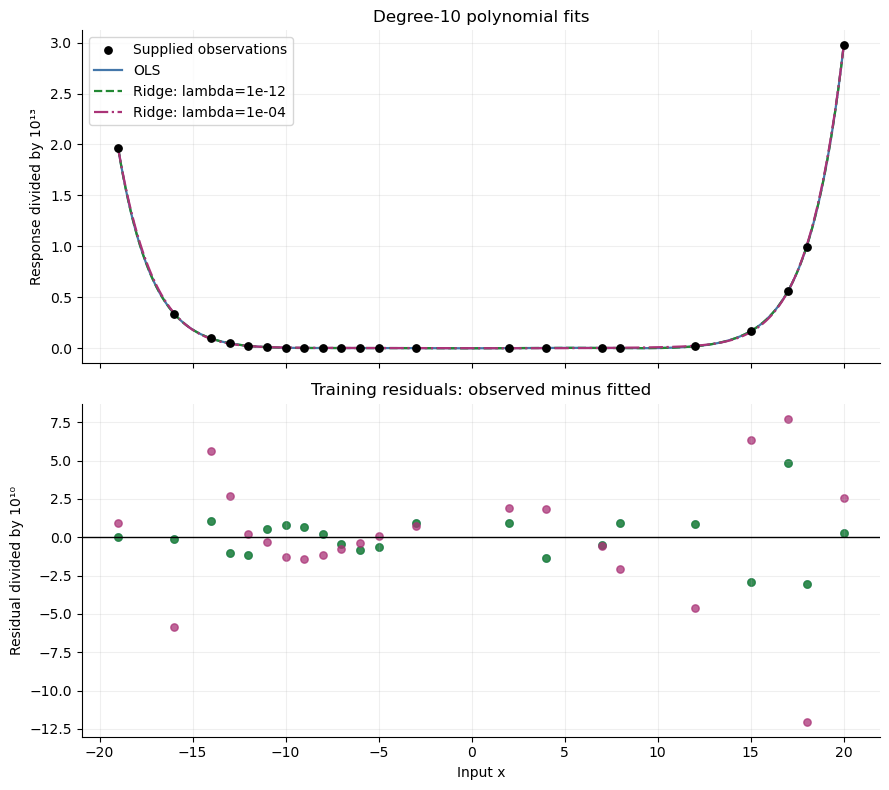

Saved: C:\Users\Usuario\Documents\DocsMain\Informatik\ComputerScienceMSc\advStatistics\workbook\figures\task05_polynomial_fits.pdf


In [7]:
x_grid = np.linspace(x.min(), x.max(), 800)
A_grid = np.vander(
    x_grid / x_scale,
    N=n_parameters,
    increasing=True,
)

styles = [
    ("OLS", beta_ols, "#4477AA", "-"),
    (
        f"Ridge: lambda={selected_penalty:.0e}",
        beta_ridge,
        "#228833",
        "--",
    ),
    (
        f"Ridge: lambda={illustrative_penalty:.0e}",
        beta_stronger,
        "#AA3377",
        "-.",
    ),
]

with plt.rc_context({
    "font.size": 10,
    "pdf.fonttype": 42,
}):
    fig, axes = plt.subplots(
        2, 1,
        figsize=(9, 8),
        sharex=True,
    )

    axes[0].scatter(
        x,
        y / y_scale,
        color="black",
        s=28,
        label="Supplied observations",
        zorder=5,
    )

    for label, beta, color, line_style in styles:
        axes[0].plot(
            x_grid,
            A_grid @ beta,
            color=color,
            linestyle=line_style,
            linewidth=1.6,
            label=label,
        )

        # obs - fitted
        residuals = y - y_scale * (A @ beta)

        axes[1].scatter(
            x,
            residuals / 1e10,
            color=color,
            s=28,
            label=label,
            alpha=0.75,
        )

    axes[0].set_title("Degree-10 polynomial fits")
    axes[0].set_ylabel("Response divided by 10¹³")
    axes[0].legend()

    axes[1].axhline(0, color="black", linewidth=1)
    axes[1].set_xlabel("Input x")
    axes[1].set_ylabel("Residual divided by 10¹⁰")
    axes[1].set_title("Training residuals: observed minus fitted")

    for ax in axes:
        ax.grid(alpha=0.2)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig.tight_layout()

    fit_pdf = figure_directory / "task05_polynomial_fits.pdf"
    fit_png = figure_directory / "task05_polynomial_fits.png"

    fig.savefig(fit_pdf, bbox_inches="tight")
    fig.savefig(fit_png, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

print(f"Saved: {fit_pdf.resolve()}")

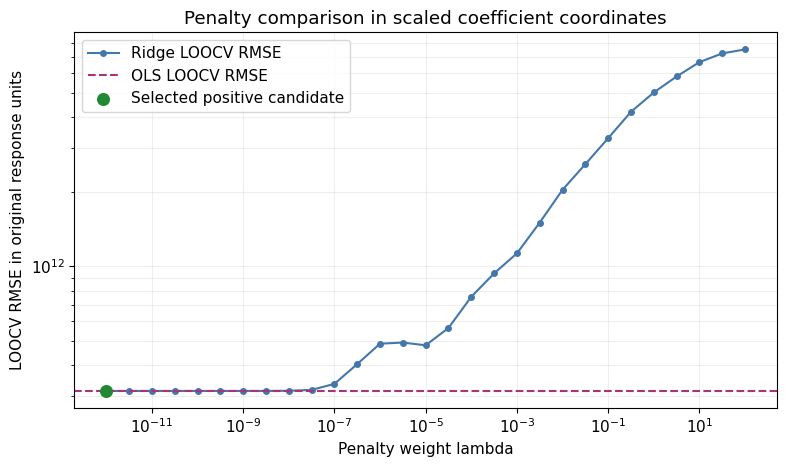

Saved: C:\Users\Usuario\Documents\DocsMain\Informatik\ComputerScienceMSc\advStatistics\workbook\figures\task05_penalty_comparison.pdf


In [8]:
with plt.rc_context({
    "font.size": 11,
    "pdf.fonttype": 42,
}):
    fig, ax = plt.subplots(figsize=(8, 4.8))

    ax.loglog(
        penalty_grid,
        ridge_cv_scores,
        marker="o",
        markersize=4,
        color="#4477AA",
        label="Ridge LOOCV RMSE",
    )

    ax.axhline(
        ols_cv_rmse,
        color="#AA3377",
        linestyle="--",
        label="OLS LOOCV RMSE",
    )

    ax.scatter(
        [selected_penalty],
        [selected_cv_rmse],
        color="#228833",
        s=70,
        zorder=5,
        label="Selected positive candidate",
    )

    ax.set_xlabel("Penalty weight lambda")
    ax.set_ylabel("LOOCV RMSE in original response units")
    ax.set_title("Penalty comparison in scaled coefficient coordinates")
    ax.grid(which="both", alpha=0.2)
    ax.legend()

    fig.tight_layout()

    cv_pdf = figure_directory / "task05_penalty_comparison.pdf"
    cv_png = figure_directory / "task05_penalty_comparison.png"

    fig.savefig(cv_pdf, bbox_inches="tight")
    fig.savefig(cv_png, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

print(f"Saved: {cv_pdf.resolve()}")

## Results and interpretation

The scaled degree-10 design matrix has full column rank, so the OLS coefficient estimate is unique.

Scaling reduces the design-matrix condition number from approximately $1.11\times10^{13}$ to $4.91\times10^3$, improving numerical conditioning. This does not by itself establish predictive accuracy.

The OLS training RMSE is approximately $1.54427\times10^{10}$, while its leave-one-out RMSE is approximately $3.14818\times10^{11}$.

Among the tested positive ridge penalties, the smallest value, $\lambda=10^{-12}$, has the lowest validation error. Its fit is
almost indistinguishable from OLS and does not improve on the OLS validation score.

Because the selected value lies at the lower boundary of the grid, the comparison does not identify a meaningful positive optimum. It provides no evidence that substantial regularization benefits this dataset under the chosen penalty convention and validation method.

For illustration, increasing the penalty to $\lambda=10^{-4}$ reduces the norm of the penalized scaled coefficients from approximately 11.463 to 3.236. However, both training and leave-one-out errors increase.

Thus, coefficient shrinkage is achieved, but shrinkage alone does not establish a better fitted model.

Among the evaluated alternatives, OLS is retained as the preferred fit. The selected positive ridge fit and the stronger ridge fit are reported to show the effect of regularization.
